In [2]:
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'

# =========================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'

color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'

line_width = 1.5
fs_r = 8000

fc = FileChooser('Señales AC3E/Femenino')
fc.layout = widgets.Layout(width='auto')
display(fc)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales AC3E\Femenino', filename='', title='', show_…

In [3]:
archivo = Path(fc.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)


señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])

b,a = sig.butter(4,65, 'hp', fs=fs_r)
señal_MBK = sig.filtfilt(b,a,señal_MBK)

señal_ACC  = -datos[:, 1]
señal_ACC  = señal_ACC - np.mean(señal_ACC)
señal_ACC = sig.filtfilt(b,a,señal_ACC) 

if max(abs(señal_ACC)) > 0:
    señal_ACC = señal_ACC / max(abs(señal_ACC)) 
#señal_ACC = sig.filtfilt(b,a,señal_ACC)

señal_EGG  = datos[:, 3]
señal_dEGG = np.gradient(señal_EGG)
señal_OVV  = datos[:, 2] - np.mean(datos[:, 2])
if max(abs(señal_OVV)) > 0:
    señal_OVV = señal_OVV / max(abs(señal_OVV)) 
if max(señal_dEGG) > 0:
    señal_dEGG = señal_dEGG / max(señal_dEGG) 

to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r);


SP = CONMF.NNMF_GIF(speech=señal_MBK,
                acelerometro=señal_ACC,
                dEGG = señal_dEGG,
                tiempos=tiempos,
                fs=fs_r,
                norma='frobenius')

SP.flujo1_speech = sig.filtfilt(b,a,SP.flujo1_speech)
SP.flujo2_speech = sig.filtfilt(b,a,SP.flujo2_speech)
SP.flujo1_acc = sig.filtfilt(b,a,SP.flujo1_acc)
SP.flujo2_acc = sig.filtfilt(b,a,SP.flujo2_acc)

SP1 = NMF.NNMF_GIF(señal_MBK,tiempos,fs_r,
            norma='frobenius',
            pre_iteraciones=0,
            iteraciones=250,
            p_filtro=12,
            alfa=0.96,
            p=12,
            pre_enfasis=True,
            duracion=5.5,
            guardar_proceso=True)

In [4]:
archivo = Path(fc.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
fs_r = 8000

señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])

b,a = sig.butter(4,65, 'hp', fs=fs_r)
señal_MBK = sig.filtfilt(b,a,señal_MBK)

señal_ACC  = -datos[:, 1]
señal_ACC  = señal_ACC - np.mean(señal_ACC)
señal_ACC = sig.filtfilt(b,a,señal_ACC) 

if max(abs(señal_ACC)) > 0:
    señal_ACC = señal_ACC / max(abs(señal_ACC)) 
#señal_ACC = sig.filtfilt(b,a,señal_ACC)

señal_EGG  = datos[:, 3]
señal_dEGG = np.gradient(señal_EGG)
señal_OVV  = datos[:, 2] - np.mean(datos[:, 2])
if max(abs(señal_OVV)) > 0:
    señal_OVV = señal_OVV / max(abs(señal_OVV)) 
if max(señal_dEGG) > 0:
    señal_dEGG = señal_dEGG / max(señal_dEGG) 

to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r);


SP = CONMF.NNMF_GIF(speech=señal_MBK,
                acelerometro=señal_ACC,
                dEGG = señal_dEGG,
                tiempos=tiempos,
                fs=fs_r,
                norma='frobenius')

SP.flujo1_speech = sig.filtfilt(b,a,SP.flujo1_speech)
SP.flujo2_speech = sig.filtfilt(b,a,SP.flujo2_speech)
SP.flujo1_acc = sig.filtfilt(b,a,SP.flujo1_acc)
SP.flujo2_acc = sig.filtfilt(b,a,SP.flujo2_acc)

SP1 = NMF.NNMF_GIF(señal_MBK,tiempos,fs_r,
            norma='frobenius',
            pre_iteraciones=0,
            iteraciones=250,
            p_filtro=12,
            alfa=0.96,
            p=12,
            pre_enfasis=True,
            duracion=5.5,
            guardar_proceso=True)

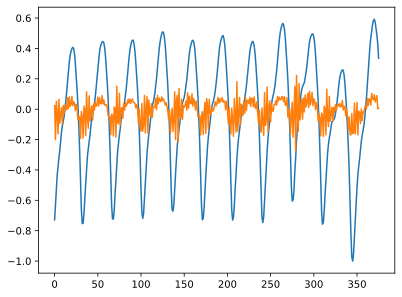

In [5]:
plt.plot(SP1.flujo1)
plt.plot(SP1.flujo2)


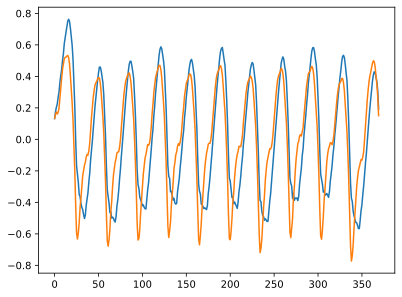

In [6]:
plt.plot(SP.flujo1_speech)
plt.plot(SP.flujo2_speech)


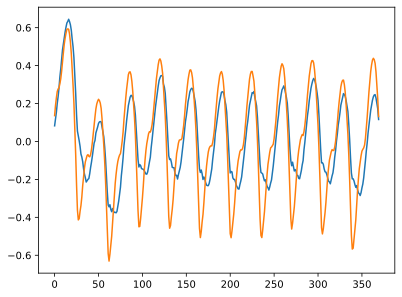

In [7]:
plt.plot(SP.flujo1_acc)
plt.plot(SP.flujo2_acc)

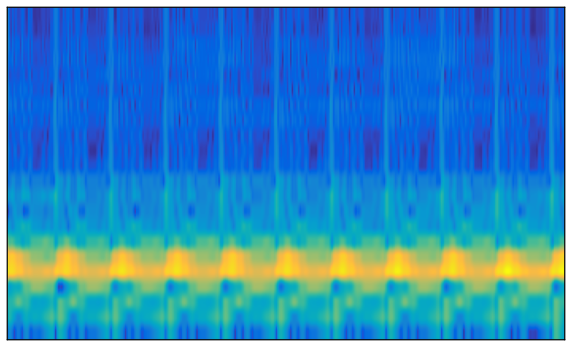

In [11]:
fig,ax=plt.subplots(figsize=(10,6))

ax.imshow(SP.espectrograma_speech_sincronizado,
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[SP.to_espectrograma_original, SP.tf_espectrograma_original,
                        SP.fo_espectrograma, SP.ff_espectrograma])
ax.set_yticks([])
ax.set_xticks([])
#fig.colorbar(im2, ax=ax2, pad=0.02)
# ------------- dEGG
ax2_ = ax.twinx()
#ax2_.plot(SP.tiempos_espectrograma_original,SP.dEGG_original,color='white', label=r"$dEGG$", linewidth=line_width)
#ax2_.legend(loc=legend_loc)
ax2_.set_xlim(SP.to_espectrograma_original, SP.tf_espectrograma_original)
ax2_.set_ylim([-2, 2])
ax2_.set_xticks(np.arange(SP.to_espectrograma_original, SP.tf_espectrograma_original, SP.duracion_ventana))
ax2_.set_yticks([])
ax2_.set_xticks([])
fig.savefig('espectrograma_speech.svg',bbox_inches = 'tight');

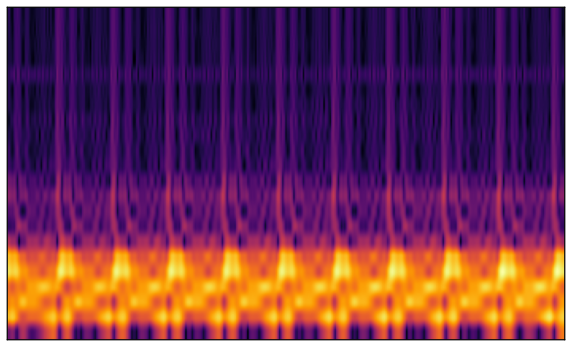

In [12]:
fig,ax=plt.subplots(figsize=(10,6))
ax.imshow(SP.espectrograma_acc_sincronizado,
                cmap='inferno',
                origin='lower',
                aspect='auto',
                extent=[SP.to_espectrograma_original, SP.tf_espectrograma_original,
                        SP.fo_espectrograma, SP.ff_espectrograma])
ax.set_yticks([])
ax.set_xticks([])
#fig.colorbar(im2, ax=ax2, pad=0.02)
# ------------- dEGG
ax2_ = ax.twinx()
#ax2_.plot(SP.tiempos_espectrograma_original,SP.dEGG_original,color='white', label=r"$dEGG$", linewidth=line_width)
#ax2_.legend(loc=legend_loc)
ax2_.set_xlim(SP.to_espectrograma_original, SP.tf_espectrograma_original)
ax2_.set_ylim([-2, 2])
ax2_.set_xticks(np.arange(SP.to_espectrograma_original, SP.tf_espectrograma_original, SP.duracion_ventana))
ax2_.set_yticks([])
ax2_.set_xticks([])
fig.savefig('espectrograma_acc.svg',bbox_inches = 'tight');

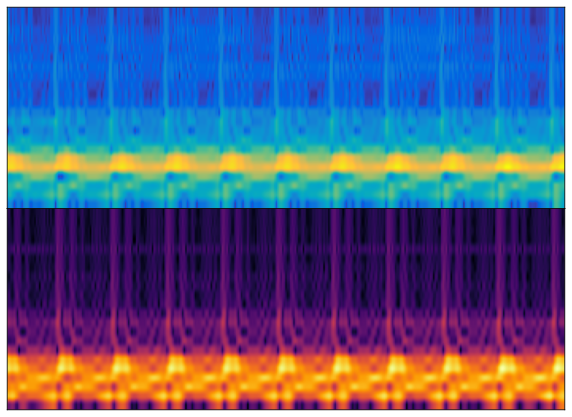

In [15]:
fig,ax=plt.subplots(2,1,figsize=(10,8))
ax1 = ax[0]
ax2 = ax[1]
pos1 = ax1.get_position()
pos2 = ax2.get_position()

# nueva altura para que "toque" al de arriba
new_height = pos1.y0 - pos2.y0

# Muevo ax7 hacia arriba justo debajo de ax2
ax2.set_position([pos2.x0, pos1.y0 - pos2.height, pos2.width, pos2.height])

ax1.imshow(SP.espectrograma_speech_sincronizado,
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[SP.to_espectrograma_original, SP.tf_espectrograma_original,
                        SP.fo_espectrograma, SP.ff_espectrograma])
#ax1.set_ylabel('Frecuencia ')
ax1.set_yticks([])
ax1.set_xticks([])


ax2.imshow(SP.espectrograma_acc_sincronizado,
                cmap='inferno',
                origin='lower',
                aspect='auto',
                extent=[SP.to_espectrograma_original, SP.tf_espectrograma_original,
                        SP.fo_espectrograma, SP.ff_espectrograma])
#ax2.set_ylabel('Frecuencia ')
ax2.set_yticks([])
ax2.set_xticks([])
fig.savefig('espectrograma_combinado.svg',bbox_inches = 'tight');

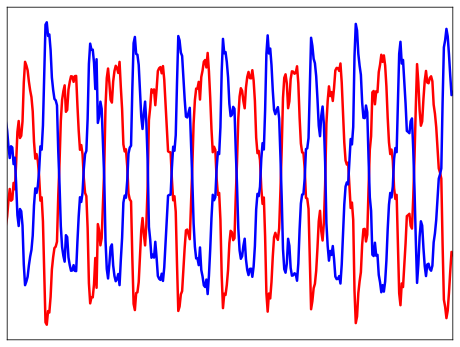

In [16]:
fig,ax3=plt.subplots(figsize=(8,6))
ax3.plot(SP.tiempos_espectrograma_sincronizado,SP.H1,color=color1,label=r'$H_1$',linewidth=2.5)
ax3.plot(SP.tiempos_espectrograma_sincronizado,SP.H2,color=color2,label=r'$H_2$',linewidth=2.5)
ax3.set_xlim(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado)
#ax3.set_xticks(np.arange(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado,SP.duracion_ventana))
#ax3.set_xticks(np.arange(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado,SP.duracion_ventana/2),minor=True)
#ax3.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
#ax3.legend(loc=legend_loc)
ax3.set_xticks([])
ax3.set_yticks([])
fig.savefig('H_combinado.svg',bbox_inches = 'tight');

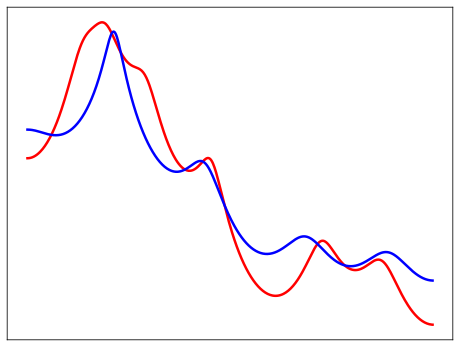

In [18]:
fig,ax4=plt.subplots(figsize=(8,6))
fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
fw1,hw1 = sig.freqz([1],SP.a_W1_speech,fs=fs_r)
fw2,hw2 = sig.freqz([1],SP.a_W2_speech,fs=fs_r)
ax4.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1,linewidth=2.5)
ax4.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2,linewidth=2.5)
#ax4.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
#ax4.set_xlim(0,fs_r/2)
#ax4.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
#ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
ax4.set_yticks([])
ax4.set_xticks([])
#ax4.legend(loc='upper right')
fig.savefig('W_speech.svg',bbox_inches = 'tight');

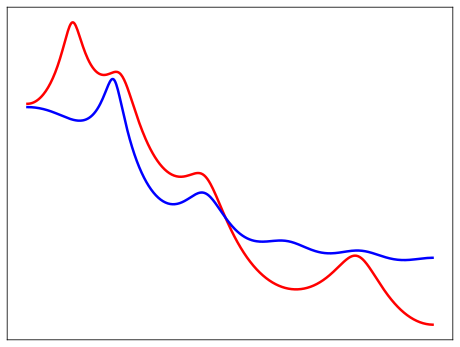

In [19]:
fig,ax4=plt.subplots(figsize=(8,6))
fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
fw1,hw1 = sig.freqz([1],SP.a_W1_acc,fs=fs_r)
fw2,hw2 = sig.freqz([1],SP.a_W2_acc,fs=fs_r)
ax4.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1,linewidth=2.5)
ax4.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2,linewidth=2.5)
#ax4.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
#ax4.set_xlim(0,fs_r/2)
#ax4.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
#ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
ax4.set_yticks([])
ax4.set_xticks([])
fig.savefig('W_acc.svg',bbox_inches = 'tight');